In [418]:
"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #03 - Statistical Objective Analysis

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using statistical objective analysis.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"

In [419]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles
import pandas as pd
import os
os.environ["PROJ_IGNORE_CELESTIAL_BODY"]="YES"

In [420]:
### Read in observations ###
df = pd.read_csv('RAOBs_201903131200.txt',sep=',',header=None)
latitude = df[1]
longitude = df[2]
df['h500'] = df[3]

In [421]:
### Set up analysis map with a 21x27 rectangular grid of points ###

nx,ny=(21, 27) #set up grid
x0=25 #initial x and y
y0=-15.5
rho=6371000 # earth's radius
m=1/15000000 #scale factor
phi0=60
lambda0=-100

yv=y0+(np.arange(ny))*1.27 # x and y coordinates of grid points, spaced 1.27cm apart
xv=x0+(np.arange(nx))*1.27
xcm, ycm=np.meshgrid(xv,yv, indexing='ij') #create grid


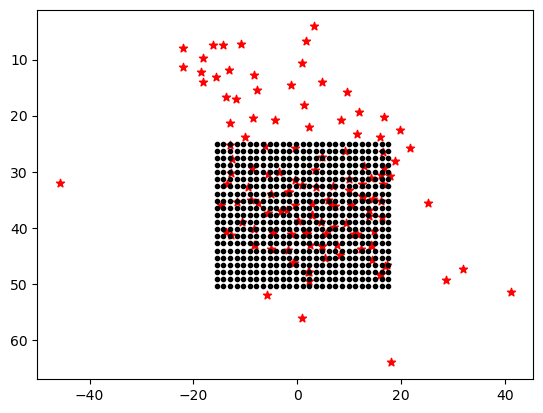

In [422]:
### convert obs lat/long to x,y ###
x=xcm/100/m
y=ycm/100/m
r=np.sqrt(x**2+y**2)

psi0=90-phi0 #psi in degrees

phi=np.pi/2-2*np.arctan(r/(rho*(1+np.cos(np.radians(psi0)))))
lam=np.arctan2(y,x) 
gridlat=np.degrees(phi) #grid points lat
gridlon=(lambda0+np.degrees(lam)+180)%360-180 #grid points lon

phi=np.radians(latitude)
lam=np.radians(longitude-lambda0)

sigma=(1+np.sin(np.radians(phi0)))/(1+np.sin(phi)) #
R=m*sigma*rho*np.cos(phi)
df['X']=100*R*np.cos(lam)
df['Y']=100*R*np.sin(lam)

plt.plot(ycm,xcm,marker='.',color='k',linestyle='none')
plt.gca().invert_yaxis()

#print (lon)
#print (ycm) #sanity check
plt.scatter(df['Y'],df['X'],marker='*',color='r')
plt.show()


In [423]:
#dik (distance between ith analysis point and kth obs point)
dik=[]
df['i']=(((df['X']-x0)/1.27)).astype(int) #set up indices
df['j']=((df['Y']-y0)/1.27).astype(int)

for i in range(21): #iterate over i
        for j in range(27): #over j, ensures running analysis for each grid point
            xi=xcm[i,j] # x coordinates for all grid points
            yi=ycm[i,j] # y coordinates for all grid points
            dfpx=df['X']-xi # x distance between grid point and obs
            dfpy=df['Y']-yi # y distance between grid point and obs
            d=np.sqrt(dfpx**2+dfpy**2) #shortest distance between point and obs
            dik.append(d)
#print (len(dik)) #sanity check, len is 567 (which is 21*27) and each has 135, so distance from every grid point to every obs point)

In [424]:
Kd = 10.8844524 #cm2
re=12.7775892 #cm

In [425]:
#cressman functions
def cressw(re,d):
    w=np.where(d<=re,(np.exp((-d**2)/Kd)),0.0)
    return w #just finds cressman weights

def cressman(x,y,xd,yd,vals,re):
    d=np.sqrt((xd-x)**2+(yd-y)**2)
    w=cressw(re,d)
    wsum=w.sum()
    if wsum==0:
        return np.nan
    return (w*vals).sum()/wsum

In [426]:
xobsloc=df['X'].values #x coordinate of obs
yobsloc=df['Y'].values #y coordinate of obs
obsheight=df['h500'].values #height of obs
Xij,Yij=xcm,ycm #grid points

In [427]:
background=np.full((nx,ny),np.nan) #1st pass, getting background field
for i in range(nx):
    for j in range(ny): #iterate over all points in grid
        background[i,j]=cressman(Xij[i,j],Yij[i,j],xobsloc,yobsloc,obsheight,re)
#print (background) #sanity check

/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


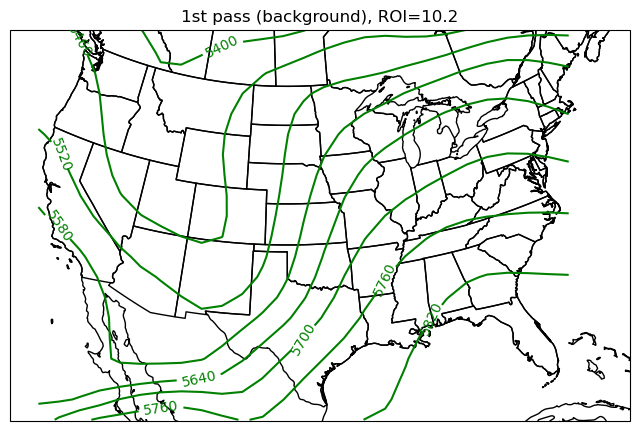

In [428]:
#plot bg sanity check
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)

levels=np.arange(0,8000,60)
cs1 = ax1.contour(gridlon,gridlat,background,colors='g',levels=np.arange(0,8000,60), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("1st pass (background), ROI=10.2")

plt.show() #sanity check yay right bg

In [429]:
#bilinear formula
def bi_interp(analysis,ifr,jfr,nx,ny):
    if np.isnan(ifr) or np.isnan(jfr):
        return np.nan
    fx=int(np.floor(ifr)) #floor x
    cx=int(np.ceil(ifr)) #ceiling x
    fy=int(np.floor(jfr)) #floor y
    cy=int(np.ceil(jfr)) #ceiling y
    if fx<0 or fy<0 or cx>nx-1 or cy>ny-1:
        return np.nan #assign NaN to points outside grid
    di=ifr-fx
    dj=jfr-fy
    #bilinear formula
    val_at_obs=(analysis[fx,fy]*(1-di)*(1-dj)+analysis[cx,fy]*di*(1-dj)+analysis[fx, cy]*(1-di)*dj+analysis[cx,cy]*di*dj)
    return val_at_obs

In [430]:
#bilinear for bg values at obs locations
df['i']=(df['X']-x0)/1.27
df['j']=(df['Y']-y0)/1.27
bgobsestimate=np.full(135,np.nan) #estimate values at observation stations pass 1 w bilinear
for k in range(135):
    v=bi_interp(background,df['i'].values[k],df['j'].values[k],nx,ny) #apply bilinear
    if np.isnan(v):
        v=cressman(xobsloc[k],yobsloc[k],Xij.ravel(),Yij.ravel(),background.ravel(),10.2) # .ravel flattens to 1D
    bgobsestimate[k]=v
#print (bgobsestimate)

In [431]:
s2 = []
ps=[]
X=100*R*np.cos(lam)
Y=100*R*np.sin(lam)
scale40=(1.0+np.sin(np.radians(phi0)))/(1.0+np.sin(np.radians(40)))
cmkm=100.0*m*scale40*1e6 #fix scale to match
b=1.24

Nstat=[2,4,10]

numval=np.isfinite(bgobsestimate) #obs locs with numerical value bg
sx=xobsloc[numval]
sy=yobsloc[numval]
obbg=obsheight[numval]-bgobsestimate[numval]

analysis=np.full((nx,ny,len(Nstat)),np.nan) #using N closest obs
for n,N in enumerate(Nstat):
    for i in range(nx):
        for j in range(ny): #iterate over all
            if np.isnan(background[i,j]):
                continue
            dgrid=np.sqrt((sx-xcm[i,j])**2+(sy-ycm[i,j])**2) #distance
            near=np.argsort(dgrid)[:N] #find closest
            xk=sx[near]
            yk=sy[near]

            skl=np.sqrt((xk[:,None]-xk[None,:])**2+(yk[:,None]-yk[None,:])**2)/cmkm
            pkl=np.where(skl==0,1.0,0.95*np.exp(-b*skl**2)) #fix to be 1 when s is 0

            ski=dgrid[near]/cmkm
            pki=np.where(ski==0,1.0,0.95*np.exp(-b*ski**2)) #fix to be 1 when s is 0

            wik=np.linalg.solve(pkl,pki)
            analysis[i,j,n]=background[i,j]+(wik*obbg[near]).sum()

In [432]:
#print (analysis[:,:,0])

/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


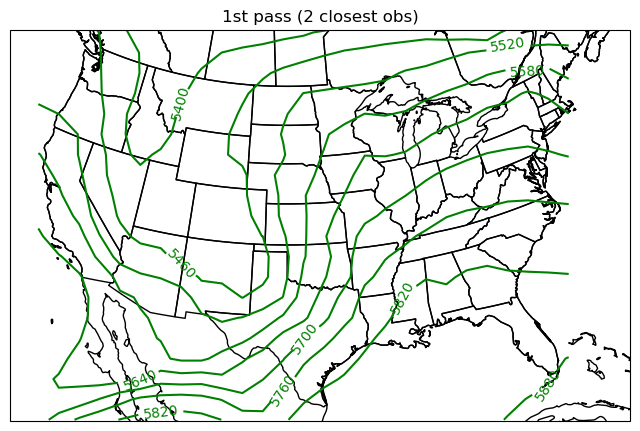

In [433]:
#plot 1st pass analysis
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)

levels=np.arange(0,8000,60)
cs1 = ax1.contour(gridlon,gridlat,analysis[:,:,0],colors='g',levels=np.arange(0,8000,60), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("1st pass (2 closest obs)")

plt.show() #sanity check yay right bg

/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


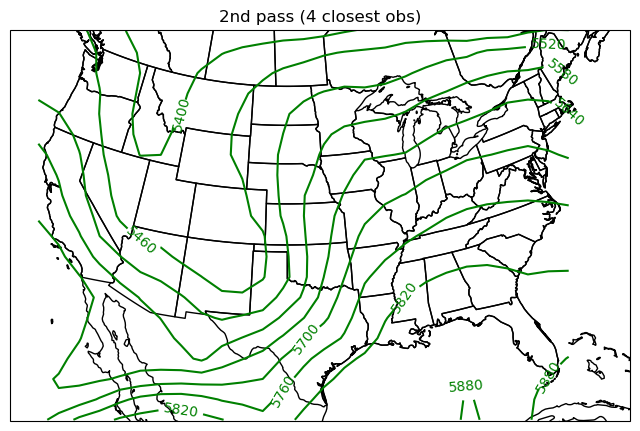

In [434]:
#plot 2nd pass analysis
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)

levels=np.arange(0,8000,60)
cs1 = ax1.contour(gridlon,gridlat,analysis[:,:,1],colors='g',levels=np.arange(0,8000,60), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("2nd pass (4 closest obs)")

plt.show() #sanity check yay right bg

/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


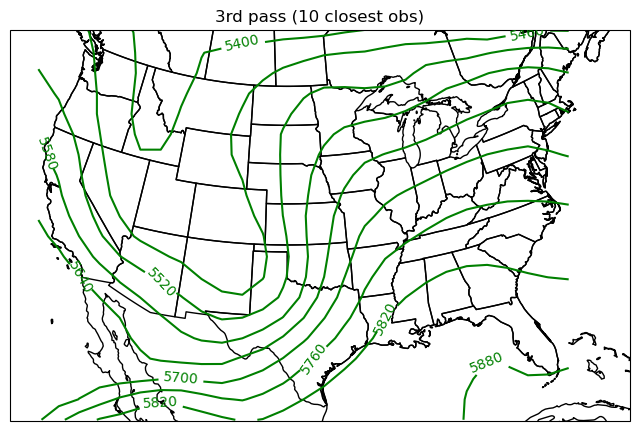

In [435]:
#plot 3rd pass analysis
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)

levels=np.arange(0,8000,60)
cs1 = ax1.contour(gridlon,gridlat,analysis[:,:,2],colors='g',levels=np.arange(0,8000,60), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("3rd pass (10 closest obs)")

plt.show() #sanity check yay right bg

In [437]:
#analysis differences
diff1=analysis[:,:,0]-background
diff2=analysis[:,:,1]-background
diff3=analysis[:,:,2]-background

Text(0.5, 1.0, 'Analysis Difference Pass 3 - background')

/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/anaconda3/envs/atsc528/lib/python3.10/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


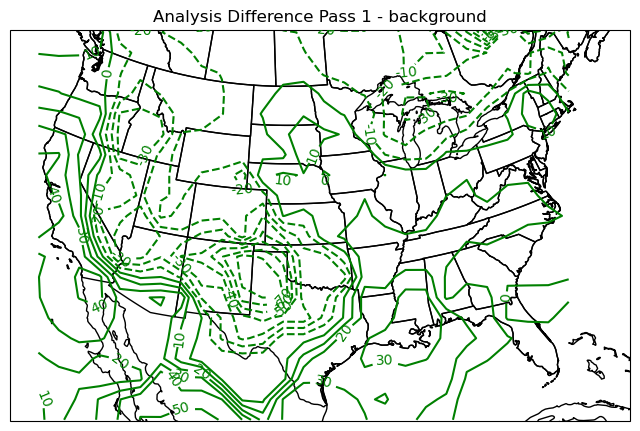

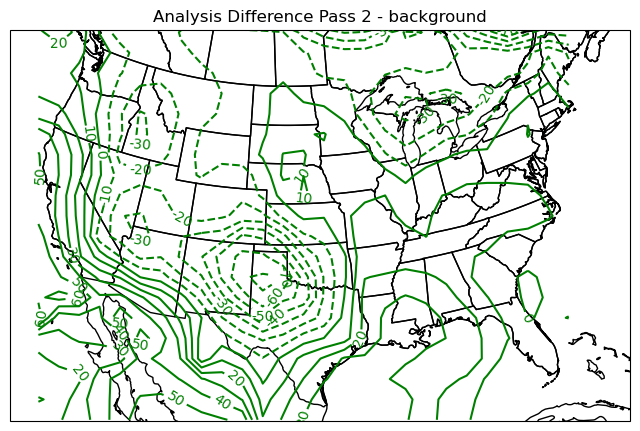

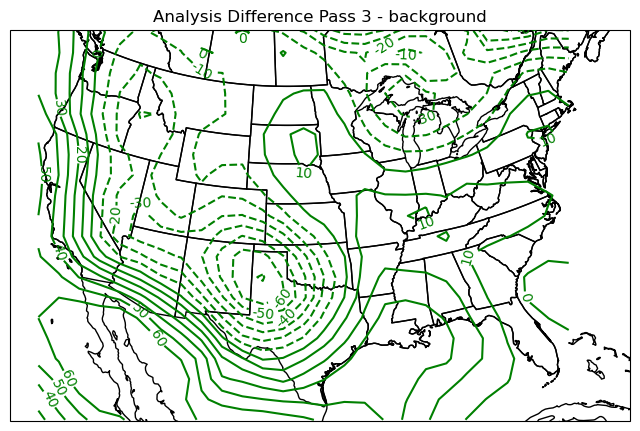

In [438]:
#plot for 1st diff field
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
# plot number of observations (MAY NEED TO CHANGE VARIABLE NAMES/INDICES) #
#levels=np.arange(-80,10,80)
cs1 = ax1.contour(gridlon,gridlat,diff1,colors='g',levels=np.arange(-70,70,10), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("Analysis Difference Pass 1 - background")

#2nd diff field
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
# plot number of observations (MAY NEED TO CHANGE VARIABLE NAMES/INDICES) #
#levels=np.arange(-80,10,80)
cs1 = ax1.contour(gridlon,gridlat,diff2,colors='g',levels=np.arange(-70,70,10), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("Analysis Difference Pass 2 - background")

#3rd diff field
globe = ccrs.Globe(ellipse=None, semimajor_axis=rho/100, semiminor_axis=rho/100)
proj = ccrs.Stereographic(central_longitude=lambda0,central_latitude=90,true_scale_latitude=phi0, globe=globe)

fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(111,projection=proj)
ax1.set_extent([-120,-75,25,50],crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.STATES)
ax1.add_feature(cfeature.COASTLINE)
# plot number of observations (MAY NEED TO CHANGE VARIABLE NAMES/INDICES) #
#levels=np.arange(-80,10,80)
cs1 = ax1.contour(gridlon,gridlat,diff3,colors='g',levels=np.arange(-70,70,10), transform=ccrs.PlateCarree(globe=globe))
plt.clabel(cs1, inline=True,fmt='%d',fontsize=10)
plt.title("Analysis Difference Pass 3 - background")

In [439]:
A1=analysis[:,:,0]
A2=analysis[:,:,1]
A3=analysis[:,:,2]

In [440]:
#bilinear for analysis values at obs locations
A1obsestimate=np.full(135,np.nan) #estimate values at observation stations pass 1 w bilinear
for k in range(135):
    v=bi_interp(A1,df['i'].values[k],df['j'].values[k],nx,ny) #apply bilinear
    if np.isnan(v):
        v=cressman(xobsloc[k],yobsloc[k],Xij.ravel(),Yij.ravel(),A1.ravel(),10.2) # .ravel flattens to 1D
    A1obsestimate[k]=v
print (A1obsestimate)

A2obsestimate=np.full(135,np.nan) #estimate values at observation stations pass 1 w bilinear
for k in range(135):
    v=bi_interp(A2,df['i'].values[k],df['j'].values[k],nx,ny) #apply bilinear
    if np.isnan(v):
        v=cressman(xobsloc[k],yobsloc[k],Xij.ravel(),Yij.ravel(),A2.ravel(),10.2) # .ravel flattens to 1D
    A2obsestimate[k]=v

A3obsestimate=np.full(135,np.nan) #estimate values at observation stations pass 1 w bilinear
for k in range(135):
    v=bi_interp(A3,df['i'].values[k],df['j'].values[k],nx,ny) #apply bilinear
    if np.isnan(v):
        v=cressman(xobsloc[k],yobsloc[k],Xij.ravel(),Yij.ravel(),A3.ravel(),10.2) # .ravel flattens to 1D
    A3obsestimate[k]=v

[5461.38549255 5551.54574347 5352.01860344 5408.63042457 5330.88581475
           nan           nan           nan 5358.4143973  5438.6087192
           nan 5440.02293736 5390.43972931 5361.5033004            nan
 5495.60767996 5355.23972966           nan 5369.4266892  5358.59608431
 5378.26582702 5358.57683217 5405.09700372 5467.35349355 5442.70460493
 5407.34684968 5436.80193163 5546.50191076           nan 5711.06427905
           nan 5467.56118648 5647.15408392 5458.68940515           nan
 5449.00823578 5615.92670425 5780.50737926           nan 5512.85369707
 5818.17892759 5779.42879137 5391.81112035 5836.53675928           nan
 5665.2521742  5761.56784592 5496.80488476           nan 5630.97041881
 5811.72869975 5806.52671633 5529.68152727 5451.15191592 5681.12715481
 5568.3402416  5450.31778821 5676.30905928 5667.07899921 5670.21531503
 5516.88133611 5879.87995884           nan 5821.34706797 5473.9821136
 5640.48086564 5674.99754744 5440.65783554 5430.92177252 5608.61105285
 5777.69

In [441]:
obslocdiff1=obsheight-A1obsestimate
obslocdiff2=obsheight-A2obsestimate
obslocdiff3=obsheight-A3obsestimate

In [442]:
#RMSEs
K1=np.sum(np.isfinite(A1obsestimate))
K2=np.sum(np.isfinite(A2obsestimate))
K3=np.sum(np.isfinite(A3obsestimate))

In [443]:
rmse1=np.sqrt(np.nansum((obsheight-A1obsestimate)**2)/K1)
rmse2=np.sqrt(np.nansum((obsheight-A2obsestimate)**2)/K2)
rmse3=np.sqrt(np.nansum((obsheight-A3obsestimate)**2)/K3)
rmse=[rmse1,rmse2,rmse3]

In [444]:
np.savetxt("N=2 analysis",A1)
np.savetxt("N=4 analysis",A2)
np.savetxt("N=10 analysis",A3)
np.savetxt("N=2 analysis increment",diff1)
np.savetxt("N=4 analysis increment",diff2)
np.savetxt("N=10 analysis increment",diff3)
np.savetxt("N=2 analysis difference",obslocdiff1)
np.savetxt("N=4 analysis difference",obslocdiff2)
np.savetxt("N=10 analysis difference",obslocdiff3)
np.savetxt("RMSEs",rmse)

In [130]:
### In a separte text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.
    The first analysis has a pronounced trough dipping down from the northwest. It inverts sharply in the central US before smoothing out to
    the northeast. Isohypses are generally equidistant, with the exception of in the main trough region (where they are more spread out) and 
    in Mexico and heading into Texas (where they are more closely spaced). The second and third analyses share these general features, with minor
    differences arising in terms of smoothness at contour inflection points.

2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?
    Compared to the 1st and 2nd analyses, the 3rd analysis appears smoother. Some of the contours in the 1st and second are jagged and
    unrealistic, most notably the contour near the Baja California peninsula (1st and 2nd) and the contours composing the eastern portion of the trough.
    This smoothing effect is likely because with each analysis, we increase the number of observations used in the analysis, so no one observation
    has a disproportionately large impact. The third analysis takes into account the greatest number of observations, so the analysis values are
    more "generalized" and representative of the overall region rather than a single point in space.

3 - What happens as you increase the number of points considered for the analysis?  Is this 
    desirable?  Why or why not?
    The analysis get smoother as the number of points considered increases. This can be desirable because it is more representative of what an actual
    atmosphere looks like. Too few points runs the risk of jagged isohypses resulting in an unphysical analysis. However, using too many observations
    can result in the analysis at one location being too impacted by distance observations. Making use of distance dependent weights can allow us 
    to resolve this and have greater confidence that the analysis is representative of observations in the immediate region
    and is not being disproportionately affected by distant observations.
    
'''

'\n1 - Describe the general features that you see in your contoured analyses.\n    The first analysis has a pronounced trough dipping down from the northwest. It inverts sharply in the central US before smoothing out to\n    the northeast. Isohypses are generally equidistant, with the exception of in the main trough region (where they are more spread out) and \n    in Mexico and heading into Texas (where they are more closely spaced). The second and third analyses share these general features. \n\n2 - Describe the differences that you see in your contoured analyses.  \n    Does one analysis seem to be smoother than the other?  If so, what would cause this?\n    Compared to the 1st and 2nd analyses, the 3rd analysis appears smoother. Some of the contours in the 1st and second are jagged and\n    unrealistic, most notably the contour near the Baja California peninsula (1st and 2nd) and the contours composing the eastern portion of the trough.\n    This smoothing effect is likely because 